# Public records partie 1 : nettoyage et analyse

Groupe 3
Participants notebook :

Fichiers : `institutional_memos`, `licensed_facilities`, `licensed_professionals`, `officer_filings` (les 5 autres sont dans le notebook `_2`)

Usage de l'IA : à compléter

In [1]:
import numpy as np
import pandas as pd

pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 1000)

## Nettoyage

On charge les 4 fichiers et on regarde les doublons et les valeurs manquantes avant de toucher à quoi que ce soit.

In [2]:
im = pd.read_csv("../data/public_records/institutional_memos.csv")
lf = pd.read_csv("../data/public_records/licensed_facilities.csv")
lp = pd.read_csv("../data/public_records/licensed_professionals.csv")
of = pd.read_csv("../data/public_records/officer_filings.csv")

dfs = {
    "institutional_memos": im,
    "licensed_facilities": lf,
    "licensed_professionals": lp,
    "officer_filings": of
}

for name, df in dfs.items():
    print(f"--- {name} : {df.shape[0]} lignes, {df.shape[1]} colonnes")
    print("doublons :", df.duplicated().sum())
    na = df.isna().sum()
    print("NaN :", na[na > 0].to_dict())
    print()

--- institutional_memos : 30 lignes, 12 colonnes
doublons : 0
NaN : {'related_purchase_order': 25, 'related_shipment_number': 22, 'related_case_number': 20}

--- licensed_facilities : 3 lignes, 12 colonnes
doublons : 0
NaN : {'license_end': 3}

--- licensed_professionals : 53 lignes, 10 colonnes
doublons : 0
NaN : {'license_expiry_date': 53, 'primary_facility_license': 26}

--- officer_filings : 136 lignes, 12 colonnes
doublons : 1
NaN : {'cessation_date': 77}



Nettoyage global : doublons, espaces en trop, dates. Il y a 2 dates qui ne sont pas au format aaaa-mm-jj, il faut faire attention avec `dayfirst` (à détailler)

In [3]:
for name, df in dfs.items():

    nb_dups = df.duplicated().sum()
    if nb_dups > 0:
        print(f"[{name}] {nb_dups} doublon(s) supprimé(s)")
        df.drop_duplicates(inplace=True)
        df.reset_index(drop=True, inplace=True)

    str_cols = df.select_dtypes(include=["object", "string"]).columns
    for col in str_cols:
        avant = df[col].copy()
        if col == "text":

            df[col] = df[col].str.replace("\r\n", "\n").str.replace(r"[ \t]+", " ", regex=True).str.strip()
        else:
            df[col] = df[col].str.replace(r"\s+", " ", regex=True).str.strip()
            modifs = avant[(avant != df[col]) & avant.notna()]
            if len(modifs) > 0:
                print(f"[{name}] {col} : {modifs.tolist()}")

    date_cols = [c for c in df.columns if "date" in c or c in ["license_start", "license_end"]]
    for col in date_cols:
        d = pd.to_datetime(df[col], format="%Y-%m-%d", errors="coerce")
        d = d.fillna(pd.to_datetime(df[col], format="mixed", dayfirst=True, errors="coerce"))
        df[col] = d

print("nettoyage global okay")

[institutional_memos] subject_line : ['  Internal  Operations  Memorandum  57 ']
[licensed_professionals] specialty : ['  environmental  assessment ']
[officer_filings] 1 doublon(s) supprimé(s)
[officer_filings] full_name : ['  Pavel  Waren ']
nettoyage global okay


In [4]:
print(lp.loc[lp["professional_name"] == "Doran Maren", "license_issue_date"])
print(of.loc[of["appointment_date"].dt.year == 1986, ["full_name", "appointment_date"]])

26   1994-07-01
Name: license_issue_date, dtype: datetime64[us]
       full_name appointment_date
57    Faris Uren       1986-01-01
59    Kira Norel       1986-01-01
133  Miran Istra       1986-01-01


Traitement spécifique à chaque fichier (sections des mémos, tranches d'âge, titre Dr....)

In [5]:
im.sort_values("document_date", inplace=True)
im.reset_index(drop=True, inplace=True)

im["nb_mots"] = im["text"].str.split().str.len()
im["visibility_level"] = pd.Categorical(im["visibility_level"], categories=["internal", "confidential", "restricted"], ordered=True)

def decoupe_sections(text):
    parts = re_titres.split(text)
    return {parts[i].strip().lower().replace(" ", "_"): parts[i + 1].strip() for i in range(1, len(parts) - 1, 2)}

import re
re_titres = re.compile(r"^([A-Z][A-Z ]{2,})$", flags=re.M)
sections = pd.DataFrame(im["text"].apply(decoupe_sections).tolist()).add_prefix("sec_")
im = pd.concat([im, sections], axis=1)

print(sections.notna().sum().sort_values(ascending=False))

sec_action                   11
sec_subject                   6
sec_context                   6
sec_facts                     5
sec_agenda                    5
sec_discussion                5
sec_decisions                 5
sec_scope                     5
sec_authorization             5
sec_supplier_and_quantity     5
sec_justification             5
sec_request                   5
sec_exception                 5
sec_cargo_and_timing          5
sec_escalation                5
sec_route                     5
sec_responsibilities          5
sec_period                    4
sec_reviewed_causes           4
sec_adjustment                4
sec_meeting_record            4
sec_discrepancy               4
sec_controls                  4
sec_legacy_system             1
sec_control_requirements      1
sec_findings                  1
sec_routing_note              1
sec_limits                    1
dtype: int64


In [6]:
print(pd.crosstab(im["author_organization"], im["visibility_level"]))

visibility_level                       internal  confidential  restricted
author_organization                                                      
Ardena Capital Union                          1             1           0
Earth Ledger Project                          0             2           0
Helix Legal and Compliance                    2             0           0
Kintara Cave and Pollinator Authority         0             1           0
Meridian BioLogistics                         1             2           4
Meridian–Asterion Foundation                  0             0           1
Nivren Maritime Logistics                     1             0           1
Northstar Cold Chain Services                 0             1           2
Solvane Energy Group                          0             1           1
Vale Strategy Collective                      1             1           1
Valenne Industrial Futures Council            2             0           0
Vosmere Biotechnics                   

In [7]:
re_ent = pd.read_csv("../data/public_records/registered_entities.csv")
lf = lf.merge(re_ent[["registration_number", "legal_name"]], left_on="operating_organization_registration", right_on="registration_number", how="left")
lf.drop(columns="registration_number", inplace=True)
lf.rename(columns={"legal_name": "operating_organization_name"}, inplace=True)

lf["declared_services"] = lf["declared_services"].str.split("; ")
lf

,facility_license_number,facility_name,facility_category,operating_organization_registration,street_address,region,latitude,longitude,license_start,license_end,facility_status,declared_services,operating_organization_name
0,FAC-VLN-101,Asterion Central Clinical Campus,research_hospital,REG-VLN-01002,"Asterion Central Clinical Campus, Valenne Cent...",Valenne Republic,47.20,7.51,2001-02-01,NaT,active,"[preventive medicine, cardiac assessment, clin...",Asterion Clinical Institute
1,FAC-AVL-201,Asterion Avelora Executive Clinic,private_clinic,REG-VLN-01002,"Asterion Avelora Executive Clinic, Eastern Ave...",Avelora Federation,7.35,101.62,2008-05-15,NaT,active,"[executive health, specialist follow-up, outpa...",Asterion Clinical Institute
2,FAC-AVL-301,Threshold Earth Avelora Laboratory,research_laboratory,REG-AVL-01007,"Threshold Earth Avelora Laboratory, Eastern Av...",Avelora Federation,7.50,101.75,2012-01-18,NaT,active,"[environmental health research, non-invasive h...",Threshold Earth Observatory


In [8]:
lp["name_clean"] = lp["professional_name"].str.replace("Dr. ", "", regex=False)

ref_date = pd.Timestamp("2026-01-01")
lp["license_age_years"] = ((ref_date - lp["license_issue_date"]).dt.days / 365.25).round(1)

print(set(lp["primary_facility_license"].dropna()) - set(lf["facility_license_number"]))

print(lp.sort_values("license_issue_date")[["license_number", "name_clean", "profession", "specialty", "license_issue_date", "license_age_years", "primary_facility_license"]].head(6))

set()
      license_number    name_clean                          profession                 specialty license_issue_date  license_age_years primary_facility_license
6   LIC-KNT-RES-1007     J. Varlan               research professional      ecological analytics         1886-07-01              139.5              FAC-AVL-301
0   LIC-VLN-MED-1001   Emil Warden                           physician                cardiology         1895-07-01              130.5              FAC-VLN-101
7   LIC-AVL-RES-1008    Jonah Bell               research professional    public policy research         1924-07-01              101.5              FAC-AVL-301
12  LIC-AVL-ADM-1013    Elira Vaun  public administration professional  programme administration         1965-07-01               60.5                      NaN
8   LIC-VLN-ENV-1009  Julien Marot          environmental professional       wildlife monitoring         1970-07-01               55.5              FAC-AVL-301
49  LIC-VLN-ADM-1050   Jalen Havel

In [9]:
annees = of["birth_year_or_age_band"].str.split("–", expand=True)
of["birth_year_min"] = annees[0].astype(int)
of["birth_year_max"] = annees[1].fillna(annees[0]).astype(int)
of["birth_year_est"] = (of["birth_year_min"] + of["birth_year_max"]) / 2
of["age_at_appointment"] = of["appointment_date"].dt.year - of["birth_year_est"]

of["is_active_mandate"] = of["cessation_date"].isna()
print(pd.crosstab(of["filing_status"], of["is_active_mandate"]))

of["mandate_duration_years"] = ((of["cessation_date"].fillna(ref_date) - of["appointment_date"]).dt.days / 365.25).round(1)

of["cessation_before_appointment"] = of["cessation_date"] < of["appointment_date"]
print("\nfin avant début :", of["cessation_before_appointment"].sum())
print(of[of["cessation_before_appointment"]][["filing_id", "full_name", "registration_number", "appointment_date", "cessation_date", "filing_date"]])

is_active_mandate  False  True 
filing_status                  
active                 0     77
historical            58      0

fin avant début : 9
      filing_id     full_name registration_number appointment_date cessation_date filing_date
35   FLG-000036    Calen Uren       REG-NDH-01011       2007-01-01     2006-12-31  2007-03-08
49   FLG-000050   Liora Corda       REG-VLN-01002       2014-01-01     2012-12-31  2014-02-23
76   FLG-000077  Jalen Quorin       REG-VLN-01002       2013-01-01     2011-12-31  2013-01-26
83   FLG-000084    Orin Norel       REG-VLN-01005       1998-01-01     1997-12-31  1998-01-26
99   FLG-000100   Pavel Waren       REG-VLN-01021       2011-01-01     2010-12-31  2011-02-03
123  FLG-000124   Elian Cevan       REG-VLN-01010       2025-01-01     2024-12-31  2025-03-04
126  FLG-000127   Daria Garen       REG-VLN-01021       2000-01-01     1998-12-31  2000-03-15
128  FLG-000129    Uma Wessen       REG-VLN-01023       2015-01-01     2014-12-31  2015-02-06
130  

In [10]:
of.sort_values(["registration_number", "appointment_date"], inplace=True)
of.reset_index(drop=True, inplace=True)

print(of.sort_values("mandate_duration_years", ascending=False)[["full_name", "birth_year_or_age_band", "role_title", "appointment_date", "cessation_date", "mandate_duration_years"]].head(8))

          full_name birth_year_or_age_band                                    role_title appointment_date cessation_date  mandate_duration_years
44     Oskar Nivren                   1946  Executive chair of Nivren Maritime Logistics       1973-01-01            NaT                    53.0
42      Edward Vann                   1815               Industrial and shipping adviser       1840-01-01     1888-12-31                    49.0
115    Celene Varro              1950–1959       Chief executive of Solvane Energy Group       1977-01-01            NaT                    49.0
113     Emil Warden                   1871               Commercial and medical investor       1895-01-01     1943-12-31                    49.0
45       Bran Grell              1940–1949                 Maritime operations executive       1980-01-01            NaT                    46.0
24      Rayan Belen                   1952                Chair of Belen Agro-Industries       1981-01-01            NaT          

In [11]:
dfs = {"institutional_memos": im, "licensed_facilities": lf, "licensed_professionals": lp, "officer_filings": of}
for name, df in dfs.items():
    print(f"{name:<24} : {df.shape[0]} lignes, {df.shape[1]} colonnes")

institutional_memos      : 30 lignes, 41 colonnes
licensed_facilities      : 3 lignes, 13 colonnes
licensed_professionals   : 53 lignes, 12 colonnes
officer_filings          : 135 lignes, 19 colonnes


Export dans `data_clean/public_records/` comme pour logistics

In [12]:
import os

output_dir = "../data_clean/public_records"
os.makedirs(output_dir, exist_ok=True)

for name, df in dfs.items():
    df.to_csv(os.path.join(output_dir, f"{name}.csv"), index=False)
    print(f" Enregistré : {output_dir}/{name}.csv ({df.shape[0]} lignes, {df.shape[1]} colonnes)")

 Enregistré : ../data_clean/public_records/institutional_memos.csv (30 lignes, 41 colonnes)
 Enregistré : ../data_clean/public_records/licensed_facilities.csv (3 lignes, 13 colonnes)
 Enregistré : ../data_clean/public_records/licensed_professionals.csv (53 lignes, 12 colonnes)
 Enregistré : ../data_clean/public_records/officer_filings.csv (135 lignes, 19 colonnes)


## Analyse

TODO : expliquer la démarche

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

re_ent = pd.read_csv("../data/public_records/registered_entities.csv", parse_dates=["registration_date", "last_filing_date"])
pa = pd.read_csv("../data/public_records/public_appointments.csv", parse_dates=["appointment_start", "appointment_end"])
sace = pd.read_csv("../data/public_records/site_access_case_events.csv")
rce = pd.read_csv("../data/public_records/regulatory_case_events.csv")

sace["event_time"] = pd.to_datetime(sace["event_time"], format="mixed")
rce["event_time"] = pd.to_datetime(rce["event_time"], format="mixed")

### Stats descriptives et outliers (CM1 / CM3)

=== license_age_years (n=53) ===
  Moyenne : 29.44 | Écart-type : 26.40
  Médiane : 23.50 | Min : -0.50 | Max : 139.50 | Q1 : 16.50 | Q3 : 31.50 | IQR : 15.00
      name_clean                          profession license_issue_date primary_facility_license  license_age_years  z_score
6      J. Varlan               research professional         1886-07-01              FAC-AVL-301              139.5     4.17
0    Emil Warden                           physician         1895-07-01              FAC-VLN-101              130.5     3.83
7     Jonah Bell               research professional         1924-07-01              FAC-AVL-301              101.5     2.73
12    Elira Vaun  public administration professional         1965-07-01                      NaN               60.5     1.18
8   Julien Marot          environmental professional         1970-07-01              FAC-AVL-301               55.5     0.99

=== mandate_duration_years (n=135) ===
  Moyenne : 18.34 | Écart-type : 13.02
  Médiane : 

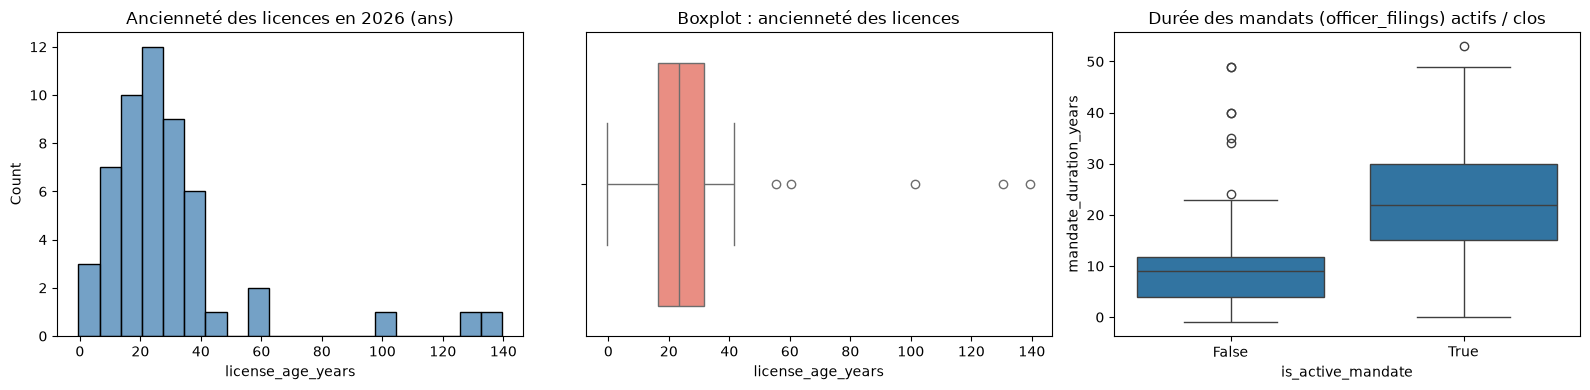

In [14]:
def stats_and_outliers(df, col, cols_affichees):
    s = df[col].dropna().astype(float)
    mean, std = s.mean(), s.std()
    med, q1, q3 = s.median(), s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1

    print(f"=== {col} (n={len(s)}) ===")
    print(f"  Moyenne : {mean:.2f} | Écart-type : {std:.2f}")
    print(f"  Médiane : {med:.2f} | Min : {s.min():.2f} | Max : {s.max():.2f} | Q1 : {q1:.2f} | Q3 : {q3:.2f} | IQR : {iqr:.2f}")

    iqr_mask = (df[col] < (q1 - 1.5 * iqr)) | (df[col] > (q3 + 1.5 * iqr))
    z_score = (df[col] - mean) / std
    outliers = df[iqr_mask | (z_score.abs() > 2.5)].copy()
    outliers["z_score"] = z_score.round(2)
    return outliers[cols_affichees + [col, "z_score"]].sort_values(col, ascending=False)

print(stats_and_outliers(lp, "license_age_years", ["name_clean", "profession", "license_issue_date", "primary_facility_license"]))
print()
print(stats_and_outliers(of, "mandate_duration_years", ["full_name", "registration_number", "role_title", "appointment_date", "cessation_date"]))
print()
print(stats_and_outliers(of, "age_at_appointment", ["full_name", "birth_year_or_age_band", "role_title", "appointment_date"]))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(lp["license_age_years"], bins=20, ax=axes[0], color="steelblue")
axes[0].set_title("Ancienneté des licences en 2026 (ans)")
sns.boxplot(x=lp["license_age_years"], ax=axes[1], color="salmon")
axes[1].set_title("Boxplot : ancienneté des licences")
sns.boxplot(x="is_active_mandate", y="mandate_duration_years", data=of, ax=axes[2])
axes[2].set_title("Durée des mandats (officer_filings) actifs / clos")
plt.tight_layout()
plt.show()

### Anomalies : fondateurs, dates, Elira Vaun

In [15]:
of_ent = of.merge(re_ent[["registration_number", "legal_name", "registration_date", "current_status"]], on="registration_number", how="left")
of_ent["avant_creation"] = of_ent["appointment_date"] < of_ent["registration_date"]
print("Nominations avant la date d'enregistrement de la société :", of_ent["avant_creation"].sum())
print(of_ent[of_ent["avant_creation"]][["full_name", "legal_name", "registration_date", "role_title", "appointment_date"]].sort_values("appointment_date"))

print("\nDirigeants des sociétés dissoutes")
print(of_ent[of_ent["current_status"] == "dissolved"][["full_name", "birth_year_or_age_band", "legal_name", "registration_date", "appointment_date", "cessation_date"]].sort_values("appointment_date"))

Nominations avant la date d'enregistrement de la société : 49
          full_name                          legal_name registration_date                                         role_title appointment_date
72       Bran Grell       Whitehaven Strategic Holdings        1987-01-15                                    Deputy director       1973-01-01
50     Oskar Nivren       Northstar Cold Chain Services        1992-01-15                        Regional logistics director       1973-03-01
81     Celene Varro  Valenne Industrial Futures Council        1984-01-15                            Industry council member       1977-05-01
82       Vera Faron  Valenne Industrial Futures Council        1984-01-15                                  Programme manager       1980-01-01
105     Miran Zorin        Meridian–Asterion Foundation        2005-01-15                                 Operations manager       1982-01-01
62       Faris Uren         Asterion Clinical Institute        1989-01-15             

In [16]:
fondateurs = of_ent[of_ent["current_status"] == "dissolved"][["full_name", "birth_year_or_age_band", "legal_name", "cessation_date"]]
fondateurs = fondateurs.merge(lp[["name_clean", "profession", "license_issue_date", "primary_facility_license"]], left_on="full_name", right_on="name_clean", how="left")
fondateurs = fondateurs.merge(lf[["facility_license_number", "facility_name"]], left_on="primary_facility_license", right_on="facility_license_number", how="left")

terrain = sace.groupby("authorized_person_name").agg(nb_events=("access_event_id", "count"), first_seen=("event_time", "min"), last_seen=("event_time", "max"))
fondateurs = fondateurs.merge(terrain, left_on="full_name", right_index=True, how="left")
print(fondateurs[["full_name", "birth_year_or_age_band", "legal_name", "cessation_date", "license_issue_date", "facility_name", "nb_events", "last_seen"]])

        full_name birth_year_or_age_band                      legal_name cessation_date license_issue_date                       facility_name  nb_events           last_seen
0      Jonah Bell                   1900        Bell Conservation Survey     1963-12-31         1924-07-01  Threshold Earth Avelora Laboratory        9.0 2025-04-18 03:00:00
1       J. Varlan                   1862   Varlan Natural History Circle     1918-12-31         1886-07-01  Threshold Earth Avelora Laboratory        9.0 2025-04-17 18:00:00
2     Edward Vann                   1815          Vann Maritime Advisory     1888-12-31                NaT                                 NaN        NaN                 NaT
3  Adrian Vosmere              1920–1929             Vosmere Biotechnics     1991-12-31                NaT                                 NaN        NaN                 NaT
4     Emil Warden                   1871         Warden Medical Ventures     1943-12-31         1895-07-01    Asterion Central Cli

In [17]:
noms_lp = set(lp["name_clean"])
sources = {
    "officer_filings": set(of["full_name"]),
    "public_appointments": set(pa["office_holder_name"]),
    "site_access": set(sace["authorized_person_name"].dropna()),
    "memos (auteurs)": set(im["author_name"].str.replace("Dr. ", "", regex=False)),
}
presence = pd.DataFrame({src: lp["name_clean"].isin(noms) for src, noms in sources.items()})
presence.index = lp["name_clean"]
presence["nb_fichiers"] = presence.sum(axis=1)
print(presence.sum())
print("\nPersonnes présentes partout :")
print(presence[presence["nb_fichiers"] >= 3].sort_values("nb_fichiers", ascending=False))

print()
print(pa[pa["office_holder_name"] == "Elira Vaun"][["office_holder_name", "office_title", "appointment_start", "appointment_end", "departure_reason"]])
print(lp[lp["name_clean"] == "Elira Vaun"][["license_number", "profession", "license_issue_date", "license_status"]])

officer_filings         40
public_appointments     22
site_access             47
memos (auteurs)          2
nb_fichiers            111
dtype: int64

Personnes présentes partout :
              officer_filings  public_appointments  site_access  memos (auteurs)  nb_fichiers
name_clean                                                                                   
Tomas Pell               True                False         True             True            3
Liora Maren              True                 True         True            False            3
Calen Uren               True                 True         True            False            3
Bela Ferran              True                False         True             True            3
Liora Corda              True                 True         True            False            3
Petra Grell              True                 True         True            False            3
Doran Maren              True                 True         True      

### Réseau des dirigeants (CM4)

On regarde qui passe d'une société à une autre

In [18]:
of_ent = of_ent.sort_values(["full_name", "appointment_date"])
of_ent["societe_suivante"] = of_ent.groupby("full_name")["legal_name"].shift(-1)
transitions = of_ent.dropna(subset=["societe_suivante"])
transitions = transitions[transitions["legal_name"] != transitions["societe_suivante"]]

print(f"{transitions['full_name'].nunique()} personnes passent d'une société à une autre")
print(pd.crosstab(transitions["legal_name"], transitions["societe_suivante"]))

27 personnes passent d'une société à une autre
societe_suivante                    Ardena Capital Union  Common Ground Climate Forum  Helix Legal and Compliance  Horizon Field Research Cooperative  Meridian BioLogistics  Nivren Maritime Logistics  Northstar Cold Chain Services  Solvane Energy Group  Valenne Industrial Futures Council  Whitehaven Strategic Holdings
legal_name                                                                                                                                                                                                                                                                                                                     
Ardena Capital Union                                   0                            0                           0                                   3                      0                          0                              0                     0                                   0                         

                                    sortants  entrants  betweenness
Whitehaven Strategic Holdings              5         1     0.036364
Ardena Capital Union                       4         2     0.036364
Valenne Industrial Futures Council         4         2     0.036364
Meridian–Asterion Foundation               4         0     0.000000
Threshold Earth Observatory                4         0     0.000000
Solvane Energy Group                       3         3     0.036364
Helix Legal and Compliance                 2         2     0.000000
Meridian BioLogistics                      1         3     0.000000
Northstar Cold Chain Services              1         5     0.009091
Nivren Maritime Logistics                  1         5     0.027273
Horizon Field Research Cooperative         1         3     0.000000
Common Ground Climate Forum                0         4     0.000000


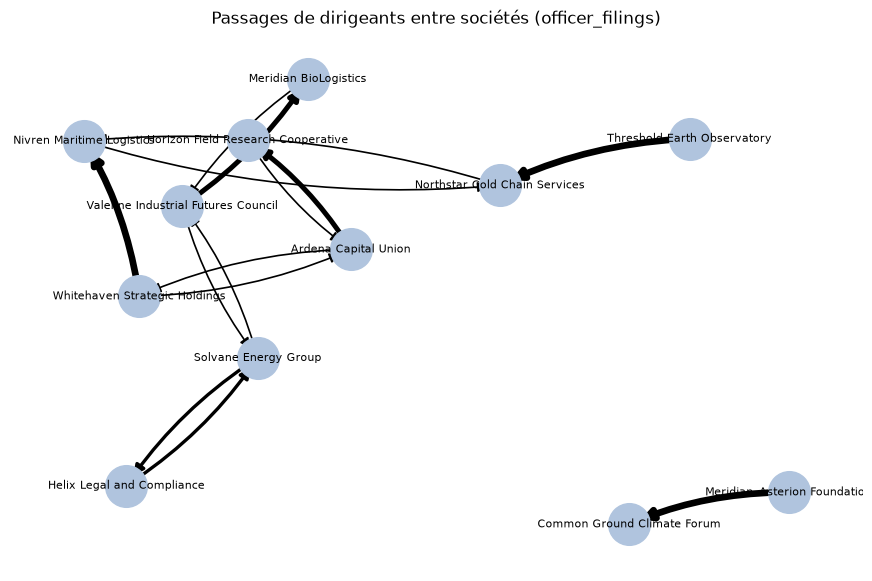

In [19]:
G = nx.DiGraph()
for _, row in transitions.iterrows():
    a, b = row["legal_name"], row["societe_suivante"]
    if G.has_edge(a, b):
        G[a][b]["weight"] += 1
    else:
        G.add_edge(a, b, weight=1)

centralite = pd.DataFrame({
    "sortants": dict(G.out_degree(weight="weight")),
    "entrants": dict(G.in_degree(weight="weight")),
    "betweenness": nx.betweenness_centrality(G),
}).sort_values("sortants", ascending=False)
print(centralite)

plt.figure(figsize=(11, 7))
pos = nx.spring_layout(G, seed=0, k=1.2)
nx.draw_networkx_nodes(G, pos, node_color="lightsteelblue", node_size=900)
nx.draw_networkx_labels(G, pos, font_size=8)
nx.draw_networkx_edges(G, pos, width=[G[u][v]["weight"] * 1.2 for u, v in G.edges()], arrows=True, arrowsize=15, connectionstyle="arc3,rad=0.1")
plt.title("Passages de dirigeants entre sociétés (officer_filings)")
plt.axis("off")
plt.show()

5 communautés, modularité = 0.642
  Communauté 1 : ['Ardena Capital Union', 'Horizon Field Research Cooperative']
  Communauté 2 : ['Nivren Maritime Logistics', 'Whitehaven Strategic Holdings']
  Communauté 3 : ['Helix Legal and Compliance', 'Meridian BioLogistics', 'Solvane Energy Group', 'Valenne Industrial Futures Council']
  Communauté 4 : ['Common Ground Climate Forum', 'Meridian–Asterion Foundation']
  Communauté 5 : ['Northstar Cold Chain Services', 'Threshold Earth Observatory']


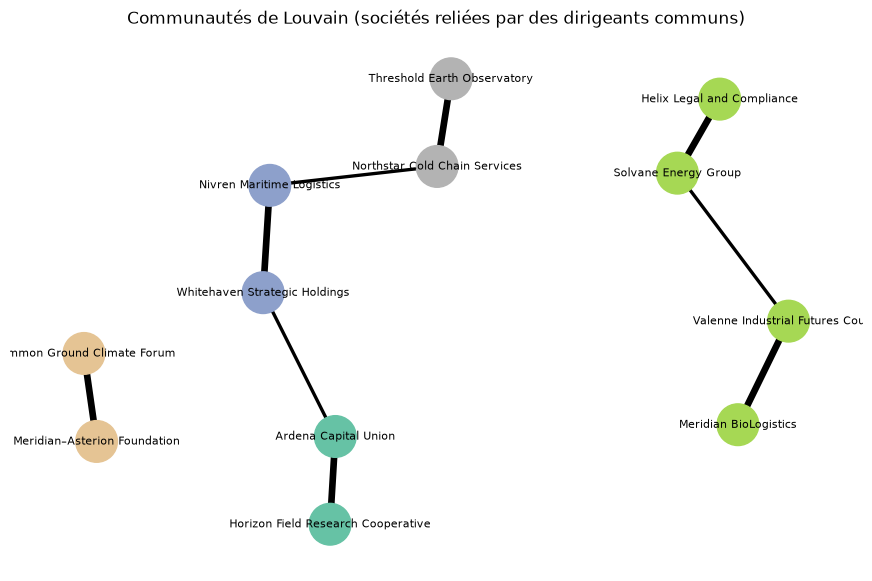

In [20]:
G_nd = nx.Graph()
for u, v, d in G.edges(data=True):
    if G_nd.has_edge(u, v):
        G_nd[u][v]["weight"] += d["weight"]
    else:
        G_nd.add_edge(u, v, weight=d["weight"])

communautes = nx.community.louvain_communities(G_nd, weight="weight", seed=0)
modularite = nx.community.modularity(G_nd, communautes, weight="weight")
print(f"{len(communautes)} communautés, modularité = {modularite:.3f}")
for k, com in enumerate(communautes):
    print(f"  Communauté {k + 1} : {sorted(com)}")

couleurs = {n: k for k, com in enumerate(communautes) for n in com}
plt.figure(figsize=(11, 7))
pos = nx.spring_layout(G_nd, seed=0, k=1.2)
nx.draw_networkx_nodes(G_nd, pos, node_color=[couleurs[n] for n in G_nd.nodes()], cmap="Set2", node_size=900)
nx.draw_networkx_labels(G_nd, pos, font_size=8)
nx.draw_networkx_edges(G_nd, pos, width=[G_nd[u][v]["weight"] * 1.2 for u, v in G_nd.edges()])
plt.title("Communautés de Louvain (sociétés reliées par des dirigeants communs)")
plt.axis("off")
plt.show()

In [21]:
B = nx.Graph()
for _, row in of_ent.iterrows():
    B.add_node(row["full_name"], bipartite="personne")
    B.add_node(row["legal_name"], bipartite="societe")
    B.add_edge(row["full_name"], row["legal_name"])

print(f"{B.number_of_nodes()} noeuds, {B.number_of_edges()} liens, {nx.number_connected_components(B)} composantes connexes")
bet = nx.betweenness_centrality(B)
cent_B = pd.DataFrame({
    "type": [B.nodes[n]["bipartite"] for n in B.nodes()],
    "degre": [B.degree(n) for n in B.nodes()],
    "betweenness": [bet[n] for n in B.nodes()],
}, index=list(B.nodes())).sort_values("betweenness", ascending=False)
print(cent_B.head(12).round(3))

print("\nComposantes isolées :", [sorted(c) for c in nx.connected_components(B) if len(c) <= 3])

128 noeuds, 131 liens, 15 composantes connexes


                                        type  degre  betweenness
Whitehaven Strategic Holdings        societe      9        0.043
Nivren Maritime Logistics            societe      5        0.034
Ardena Capital Union                 societe      9        0.034
Northstar Cold Chain Services        societe      6        0.033
Oskar Nivren                        personne      2        0.033
Adrienne Solva                      personne      2        0.032
Valenne Industrial Futures Council   societe      9        0.021
Solvane Energy Group                 societe      9        0.020
Threshold Earth Observatory          societe      9        0.020
Celene Varro                        personne      2        0.016
Marek Jaren                         personne      2        0.007
Bran Grell                          personne      2        0.007

Composantes isolées : [['Adrian Vosmere', 'Vosmere Biotechnics'], ['Edward Vann', 'Vann Maritime Advisory'], ['Emil Warden', 'Warden Medical Ventures'], [

### Profils des dirigeants : corrélations, ACP, CAH (CM1 / CM2)

Une ligne = une personne. A justifier : choix des variables, peu de lignes (104)

In [22]:
personnes = of_ent.groupby("full_name").agg(
    naissance=("birth_year_est", "first"),
    premiere_nomination=("appointment_date", "min"),
    annees_cumulees=("mandate_duration_years", lambda s: s.clip(lower=0).sum()),
    nb_mandats=("filing_id", "count"),
    nb_societes=("registration_number", "nunique"),
    actif=("is_active_mandate", "max"),
)
personnes["age_premiere_nomination"] = personnes["premiere_nomination"].dt.year - personnes["naissance"]

personnes["nb_events_terrain"] = personnes.index.map(sace["authorized_person_name"].value_counts()).fillna(0)
personnes["anciennete_licence"] = personnes.index.map(lp.set_index("name_clean")["license_age_years"]).fillna(0)
personnes["actif"] = personnes["actif"].astype(int)

variables = ["naissance", "age_premiere_nomination", "annees_cumulees", "nb_mandats", "nb_societes", "actif", "nb_events_terrain", "anciennete_licence"]
print(personnes[variables].describe().T.round(2))

                         count     mean    std     min      25%     50%      75%     max
naissance                104.0  1968.27  25.40  1815.0  1963.75  1974.0  1983.25  1994.0
age_premiere_nomination  104.0    27.27   4.10    19.5    24.00    26.5    30.50    37.0
annees_cumulees          104.0    23.83  14.98     0.0    14.00    22.0    34.00    78.8
nb_mandats               104.0     1.30   0.52     1.0     1.00     1.0     2.00     3.0
nb_societes              104.0     1.26   0.44     1.0     1.00     1.0     2.00     2.0
actif                    104.0     0.74   0.44     0.0     0.00     1.0     1.00     1.0
nb_events_terrain        104.0     3.07   4.49     0.0     0.00     0.0     7.00    15.0
anciennete_licence       104.0    11.65  23.44    -0.5     0.00     0.0    19.50   139.5


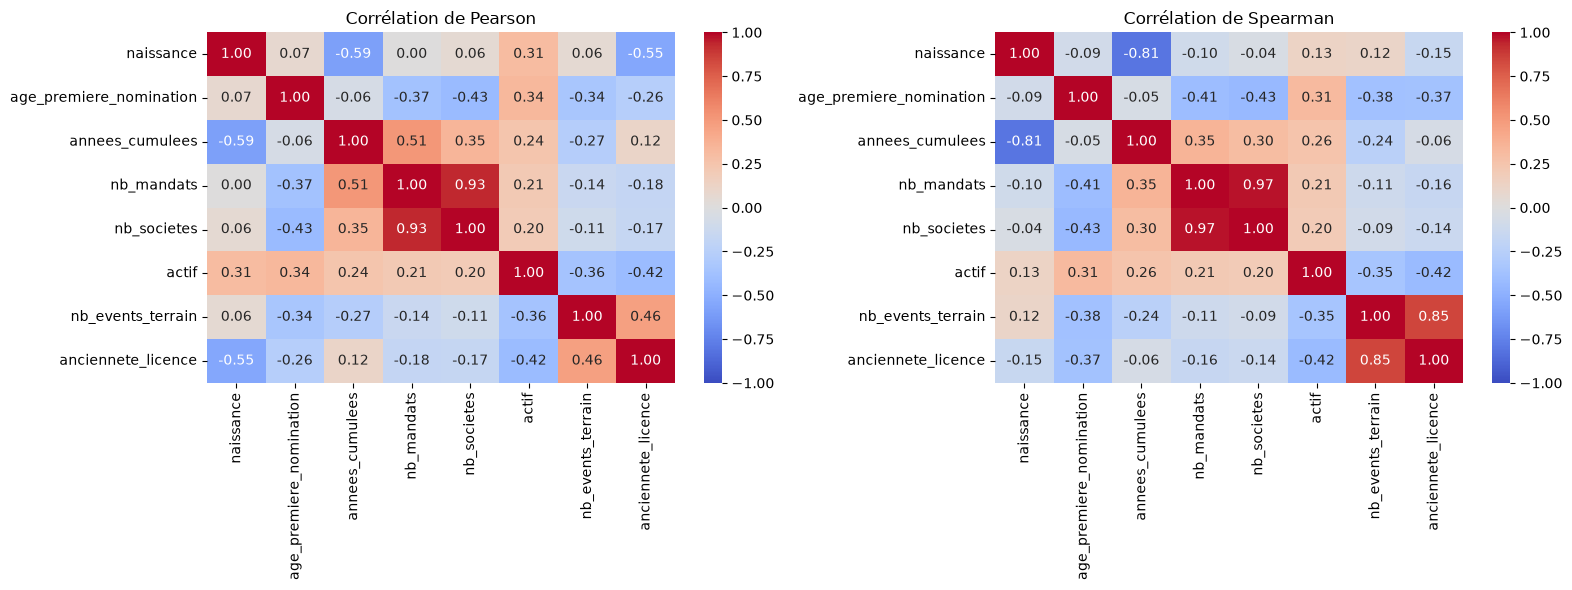

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, methode in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(personnes[variables].corr(method=methode), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
    ax.set_title(f"Corrélation de {methode.capitalize()}")
plt.tight_layout()
plt.show()

Variance expliquée : [32.1 28.1 19.9  8.5  4.9  4.   1.9  0.5]
Cumulée            : [ 32.1  60.3  80.1  88.7  93.5  97.6  99.5 100. ]
                          PC1   PC2
naissance               -0.00 -0.44
age_premiere_nomination -0.14 -0.43
annees_cumulees          0.39  0.23
nb_mandats               0.57  0.15
nb_societes              0.54  0.15
actif                    0.30 -0.40
nb_events_terrain       -0.26  0.32
anciennete_licence      -0.23  0.51


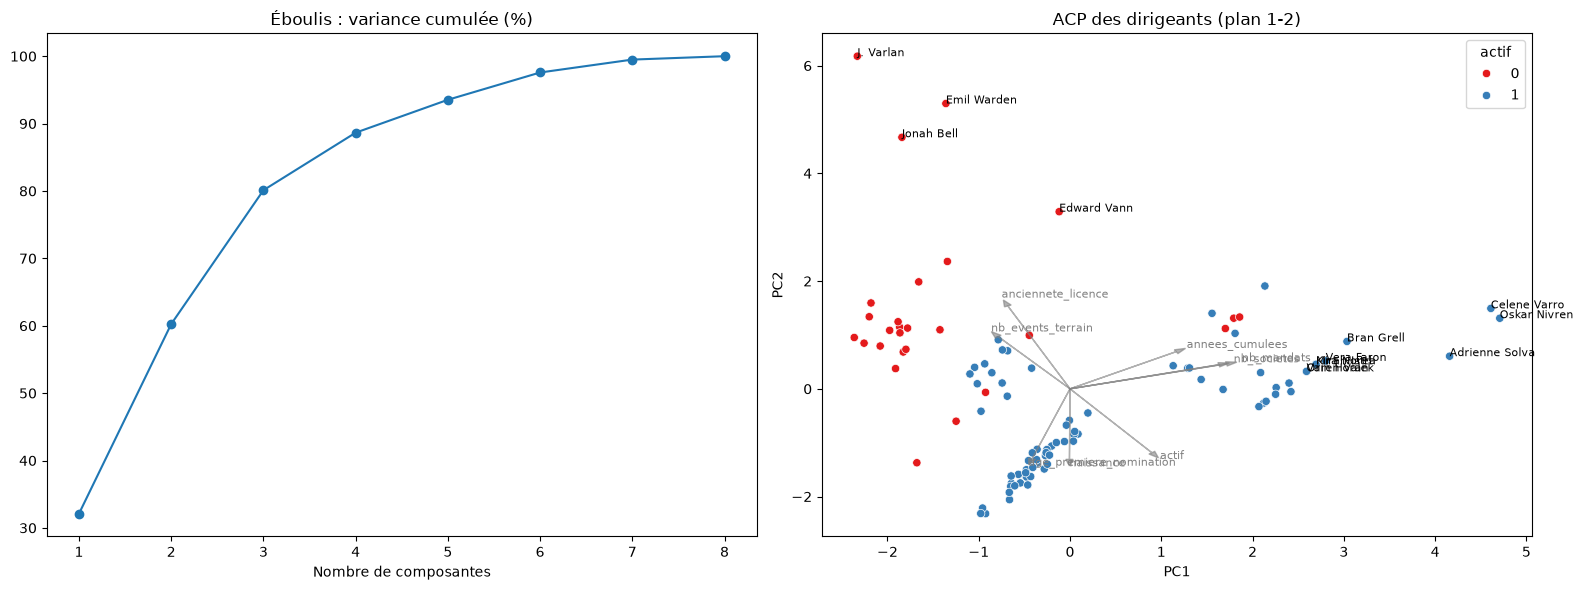

In [24]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X = StandardScaler().fit_transform(personnes[variables])

acp = PCA()
coords = acp.fit_transform(X)
print("Variance expliquée :", (acp.explained_variance_ratio_ * 100).round(1))
print("Cumulée            :", (acp.explained_variance_ratio_.cumsum() * 100).round(1))

print(pd.DataFrame(acp.components_[:2].T, index=variables, columns=["PC1", "PC2"]).round(2))

personnes["PC1"], personnes["PC2"] = coords[:, 0], coords[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].plot(range(1, len(variables) + 1), acp.explained_variance_ratio_.cumsum() * 100, marker="o")
axes[0].set_title("Éboulis : variance cumulée (%)")
axes[0].set_xlabel("Nombre de composantes")

sns.scatterplot(x="PC1", y="PC2", hue="actif", data=personnes, ax=axes[1], palette="Set1")
for nom, row in personnes[(personnes["PC1"].abs() > 2.5) | (personnes["PC2"].abs() > 2.5)].iterrows():
    axes[1].annotate(nom, (row["PC1"], row["PC2"]), fontsize=8)
for i, var in enumerate(variables):
    axes[1].arrow(0, 0, acp.components_[0, i] * 3, acp.components_[1, i] * 3, color="grey", alpha=0.6, head_width=0.08)
    axes[1].text(acp.components_[0, i] * 3.3, acp.components_[1, i] * 3.3, var, fontsize=8, color="grey")
axes[1].set_title("ACP des dirigeants (plan 1-2)")
plt.tight_layout()
plt.show()

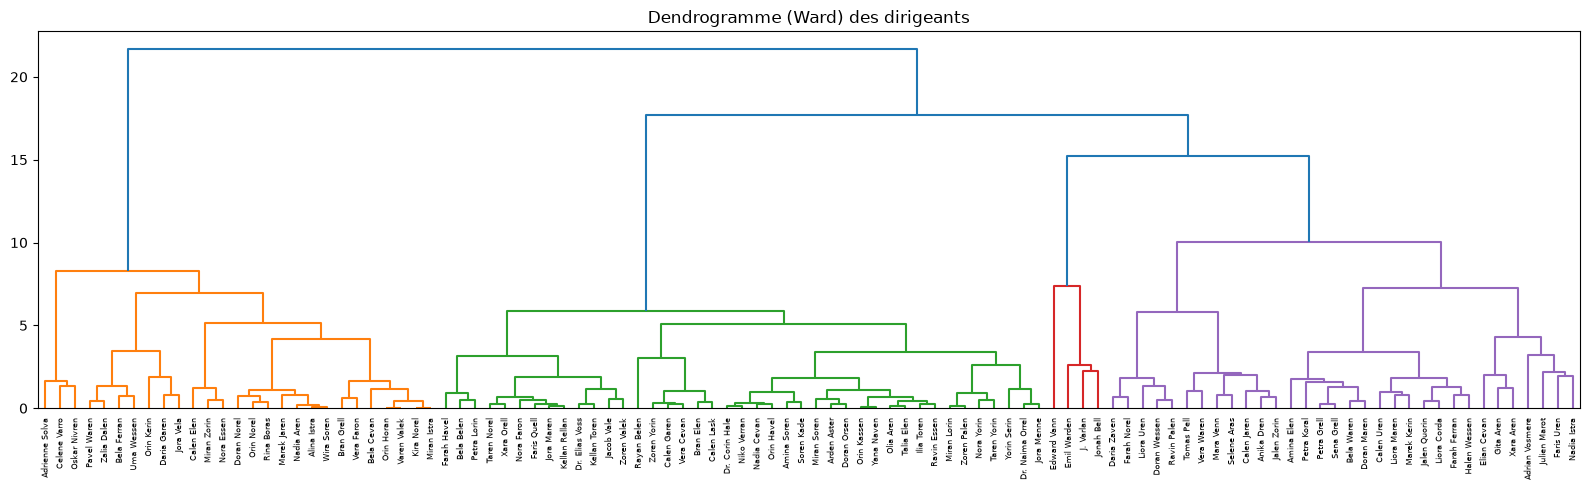

     naissance  age_premiere_nomination  annees_cumulees  nb_mandats  nb_societes  actif  nb_events_terrain  anciennete_licence
cah                                                                                                                            
1       1970.6                     24.3             32.7         2.1          2.0    0.9                2.3                 5.1
2       1974.3                     30.5             21.5         1.0          1.0    1.0                0.0                -0.0
3       1862.0                     24.0             43.0         1.0          1.0    0.0                4.5                92.9
4       1971.9                     26.0             17.0         1.0          1.0    0.4                7.5                22.0
cah
1    27
2    41
3     4
4    32
Name: count, dtype: int64


In [25]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

Z = linkage(X, method="ward")
plt.figure(figsize=(16, 5))
dendrogram(Z, labels=personnes.index.tolist(), leaf_font_size=6, color_threshold=0.7 * Z[:, 2].max())
plt.title("Dendrogramme (Ward) des dirigeants")
plt.tight_layout()
plt.show()

personnes["cah"] = fcluster(Z, t=4, criterion="maxclust")
print(personnes.groupby("cah")[variables].mean().round(1))
print(personnes["cah"].value_counts().sort_index())

### DBSCAN et LOF (CM3)

TODO : expliquer le choix de eps et du nombre de voisins

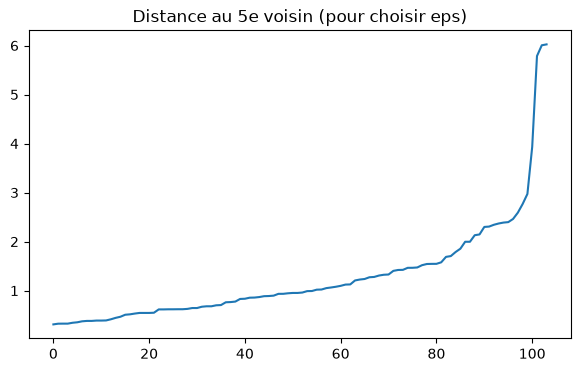

eps=1.0 : 4 cluster(s), 33 points de bruit
eps=1.5 : 4 cluster(s), 18 points de bruit
eps=2.0 : 3 cluster(s), 12 points de bruit


LOF k=10 : 15 outliers
LOF k=20 : 14 outliers
LOF k=30 : 8 outliers


In [26]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors

dist, _ = NearestNeighbors(n_neighbors=5).fit(X).kneighbors(X)
plt.figure(figsize=(7, 4))
plt.plot(np.sort(dist[:, -1]))
plt.title("Distance au 5e voisin (pour choisir eps)")
plt.show()

for eps in [1.0, 1.5, 2.0]:
    lab = DBSCAN(eps=eps, min_samples=5).fit_predict(X)
    print(f"eps={eps} : {len(set(lab)) - (1 if -1 in lab else 0)} cluster(s), {(lab == -1).sum()} points de bruit")

personnes["dbscan"] = DBSCAN(eps=1.5, min_samples=5).fit_predict(X)

for k in [10, 20, 30]:
    lab = LocalOutlierFactor(n_neighbors=k).fit_predict(X)
    print(f"LOF k={k} : {(lab == -1).sum()} outliers")

lof = LocalOutlierFactor(n_neighbors=20)
personnes["lof"] = lof.fit_predict(X)
personnes["lof_score"] = -lof.negative_outlier_factor_

DBSCAN : 18 | LOF : 14 | les deux : 9
                naissance  age_premiere_nomination  annees_cumulees  nb_societes  nb_events_terrain  anciennete_licence  dbscan  lof  lof_score
full_name                                                                                                                                      
Edward Vann        1815.0                     25.0             49.0            1                0.0                 0.0      -1   -1       2.86
J. Varlan          1862.0                     23.0             34.0            1                9.0               139.5      -1   -1       2.13
Emil Warden        1871.0                     24.0             49.0            1                0.0               130.5      -1   -1       2.13
Adrian Vosmere     1924.5                     27.5             40.0            1                0.0                 0.0      -1   -1       2.03
Elian Cevan        1992.0                     33.0              0.0            1                0.

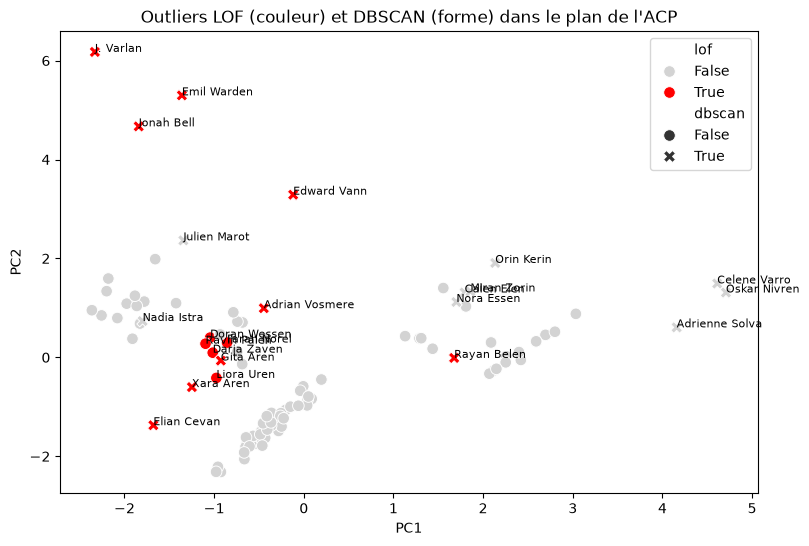

In [27]:
outliers = personnes[(personnes["dbscan"] == -1) | (personnes["lof"] == -1)]
print(f"DBSCAN : {(personnes['dbscan'] == -1).sum()} | LOF : {(personnes['lof'] == -1).sum()} | les deux : {((personnes['dbscan'] == -1) & (personnes['lof'] == -1)).sum()}")
print(outliers.sort_values("lof_score", ascending=False)[["naissance", "age_premiere_nomination", "annees_cumulees", "nb_societes", "nb_events_terrain", "anciennete_licence", "dbscan", "lof", "lof_score"]].round(2))

plt.figure(figsize=(9, 6))
sns.scatterplot(x="PC1", y="PC2", data=personnes, hue=personnes["lof"] == -1, style=personnes["dbscan"] == -1, palette={True: "red", False: "lightgrey"}, s=70)
for nom, row in outliers.iterrows():
    plt.annotate(nom, (row["PC1"], row["PC2"]), fontsize=8)
plt.title("Outliers LOF (couleur) et DBSCAN (forme) dans le plan de l'ACP")
plt.show()

### Évolution dans le temps (CM5)

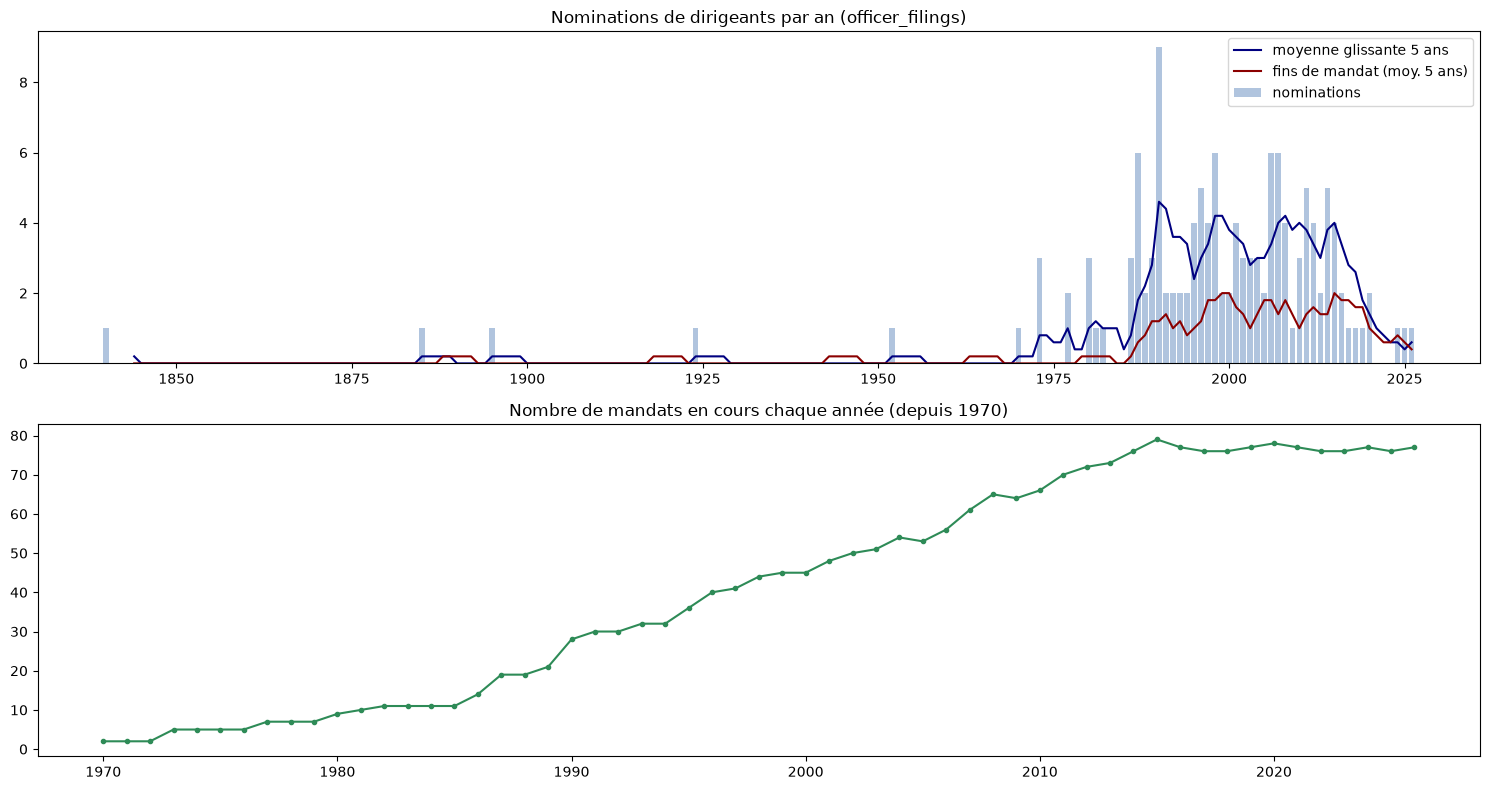

Années avec le plus de nominations :
appointment_date
1990    9
1998    6
1987    6
2006    6
2007    6
dtype: int64


In [28]:
nominations = of_ent.groupby(of_ent["appointment_date"].dt.year).size()
nominations = nominations.reindex(range(nominations.index.min(), 2027), fill_value=0)
fins = of_ent.groupby(of_ent["cessation_date"].dt.year).size().reindex(nominations.index, fill_value=0)

fig, axes = plt.subplots(2, 1, figsize=(15, 8))
axes[0].bar(nominations.index, nominations, color="lightsteelblue", label="nominations")
axes[0].plot(nominations.rolling(5).mean(), color="navy", label="moyenne glissante 5 ans")
axes[0].plot(fins.rolling(5).mean(), color="darkred", label="fins de mandat (moy. 5 ans)")
axes[0].set_title("Nominations de dirigeants par an (officer_filings)")
axes[0].legend()

mandats_actifs = pd.Series({an: ((of_ent["appointment_date"].dt.year <= an) & (of_ent["cessation_date"].fillna(ref_date).dt.year >= an)).sum() for an in range(1970, 2027)})
axes[1].plot(mandats_actifs, marker=".", color="seagreen")
axes[1].set_title("Nombre de mandats en cours chaque année (depuis 1970)")
plt.tight_layout()
plt.show()

print("Années avec le plus de nominations :")
print(nominations.sort_values(ascending=False).head(5))

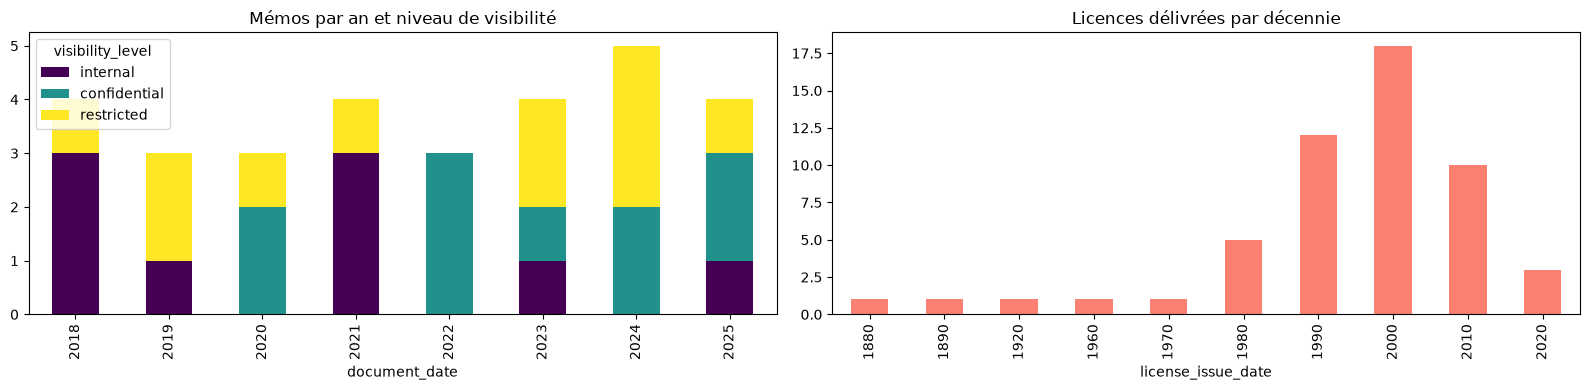

visibility_level  internal  confidential  restricted
document_date                                       
2018                     3             0           1
2019                     1             0           2
2020                     0             2           1
2021                     3             0           1
2022                     0             3           0
2023                     1             1           2
2024                     0             2           3
2025                     1             2           1


In [29]:
memos_an = pd.crosstab(im["document_date"].dt.year, im["visibility_level"])
licences_dec = lp.groupby((lp["license_issue_date"].dt.year // 10) * 10).size()

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
memos_an.plot(kind="bar", stacked=True, ax=axes[0], colormap="viridis")
axes[0].set_title("Mémos par an et niveau de visibilité")
licences_dec.plot(kind="bar", ax=axes[1], color="salmon")
axes[1].set_title("Licences délivrées par décennie")
plt.tight_layout()
plt.show()
print(memos_an)

### Mémos : liens avec les dossiers et text mining

In [30]:
refs = im[["document_id", "document_date", "author_organization", "visibility_level", "related_purchase_order", "related_shipment_number", "related_case_number"]]

acc = refs[refs["related_case_number"].str.startswith("ACC", na=False)]
acc = acc.merge(sace.groupby("access_case_number").agg(
    site=("site_code", "first"),
    organisation=("requesting_organization_name", "first"),
    personne=("authorized_person_name", "first"),
    equipement=("equipment_category", "first"),
    confidentialite=("confidentiality_class", "first"),
), left_on="related_case_number", right_index=True, how="left")
print("Mémos -> site_access")
print(acc[["document_id", "author_organization", "visibility_level", "related_case_number", "site", "organisation", "personne", "equipement", "confidentialite"]].to_string(index=False))

reg = refs[refs["related_case_number"].str.startswith("REG", na=False)]
reg = reg.merge(rce.groupby("case_number").agg(
    sujet=("subject_name", "first"),
    source=("initiating_source", "first"),
    trace=("activity", lambda s: " -> ".join(s)),
    issue=("outcome", "last"),
), left_on="related_case_number", right_index=True, how="left")
print("\nMémos -> regulatory_cases")
print(reg[["document_id", "author_organization", "visibility_level", "related_case_number", "sujet", "source", "issue"]].to_string(index=False))

Mémos -> site_access
document_id           author_organization visibility_level related_case_number    site                       organisation    personne                    equipement confidentialite
 MEM-510013 Northstar Cold Chain Services       restricted       ACC-2023-0028 KNT-WUQ      Avelora Food Standards Office Selene Aras              camera equipment    confidential
 MEM-510067  Meridian–Asterion Foundation       restricted       ACC-2020-0008 AVL-ORR Horizon Field Research Cooperative   Mara Venn acoustic and camera equipment    confidential
 MEM-510022 Whitehaven Strategic Holdings     confidential       ACC-2023-0047 AVL-KAR  Tembara Customs Coordination Unit Jalen Havel             maintenance tools        standard
 MEM-510021     Nivren Maritime Logistics       restricted       ACC-2018-0024 KNT-JQG      Nordhaven Refrigeration Works  Elira Vaun             maintenance tools        standard
 MEM-510030      Vale Strategy Collective       restricted       ACC-2019-0005 

In [31]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

vectorizer = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), max_features=500, min_df=2)
tfidf = vectorizer.fit_transform(im["text"])
mots = vectorizer.get_feature_names_out()

for niveau in ["internal", "confidential", "restricted"]:
    mask = (im["visibility_level"] == niveau).to_numpy()
    moy = np.asarray(tfidf[mask].mean(axis=0)).ravel()
    print(f"{niveau:<13}: {', '.join(mots[i] for i in moy.argsort()[::-1][:12])}")

lsa = TruncatedSVD(n_components=3, random_state=42)
lsa.fit(tfidf)
print()
for k, comp in enumerate(lsa.components_):
    print(f"Topic {k + 1} : {', '.join(mots[i] for i in comp.argsort()[::-1][:10])}")

internal     : ordinary, records, supplier, owner, onboarding, supplier onboarding, timing, procurement, reviewed, documentation, delay, substitution
confidential : records, ordinary, handling, shipment, procurement, supplier, timing, owner, cargo, secure records, records handling, exception
restricted   : records, ordinary, review, approval, restricted, inventory, staff, governance, adjustment, posting, record, shipment

Topic 1 : ordinary, records, supplier, owner, shipment, procurement, timing, posting, adjustment, handling
Topic 2 : request, quantity, written review, written, authorized, supplier unit, authorized written, authorization proceed, stock expected, stock
Topic 3 : cargo, quantity, receiving, destination, review operational, carrier note, window, carrier, window exception, scan posted


In [32]:
mots_cles = ["chameleo", "biological", "sealed", "restricted", "legacy", "do not"]
recherche = pd.DataFrame({m: im["text"].str.lower().str.contains(m, regex=False) for m in mots_cles})
recherche["visibility_level"] = im["visibility_level"]
print(recherche.groupby("visibility_level", observed=True).sum().T)

for _, row in im[im["visibility_level"] == "restricted"].iterrows():
    print("\n" + "=" * 30, row["document_id"], "|", row["document_date"].date(), "|", row["author_name"], "|", row["author_organization"], "=" * 30)
    print(row["subject_line"])
    print(row["text"])

visibility_level  internal  confidential  restricted
chameleo                 1             0           2
biological               0             0           2
sealed                   0             0           2
restricted               7             8          10
legacy                   1             0           0
do not                   1             2           1

============================== MEM-510128 | 2018-05-15 | Adrian Vosmere | Vosmere Biotechnics ==============================
Internal Operations Memorandum 56
SUBJECT
Operational review of cold-chain reconciliation.

CONTEXT
Records SHP-2020-00019 were checked against the ordinary approval path.

FACTS
Dates, quantities, and facility codes are consistent. One document arrived after the accounting cut-off and requires a visible late-posting note.

ACTION
The process owner will attach the source record and close the review after second-person approval.

The operational issue concerns cold-chain reconciliation and was revie